In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
DATA_FILE = Path("../data/raw/online_retail_II.xlsx")

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset nahi mili: {DATA_FILE.resolve()}\n"
        "Check karo ki Excel file data/raw folder mein hai."
    )

print("Dataset found:", DATA_FILE.resolve())

Dataset found: D:\loyality_reward_optimization\data\raw\online_retail_II.xlsx


In [4]:
! python -m pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
excel_file = pd.ExcelFile(DATA_FILE)

print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['Year 2009-2010', 'Year 2010-2011']


In [8]:
df_2009 = pd.read_excel(
    DATA_FILE,
    sheet_name="Year 2009-2010"
)

display(df_2009.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [9]:
df_2010 = pd.read_excel(
    DATA_FILE,
    sheet_name="Year 2010-2011"
)

print("First sheet shape:", df_2009.shape)
print("Second sheet shape:", df_2010.shape)

First sheet shape: (525461, 8)
Second sheet shape: (541910, 8)


In [10]:
df_2009 = df_2009.copy()
df_2010 = df_2010.copy()

df_2009["source_sheet"] = "Year 2009-2010"
df_2010["source_sheet"] = "Year 2010-2011"

df = pd.concat([df_2009, df_2010], ignore_index=True)

print("Combined DataFrame shape:", df.shape)
df.head()

Combined DataFrame shape: (1067371, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


In [11]:
print(df.head(10))
print(df.tail(10))
print(df.sample(5, random_state=42))

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   
5  489434     22064           PINK DOUGHNUT TRINKET POT         24   
6  489434     21871                  SAVE THE PLANET MUG        24   
7  489434     21523   FANCY FONT HOME SWEET HOME DOORMAT        10   
8  489435     22350                            CAT BOWL         12   
9  489435     22349       DOG BOWL , CHASING BALL DESIGN        12   

          InvoiceDate  Price  Customer ID         Country    source_sheet  
0 2009-12-01 07:45:00   6.95    13,085.00  United Kingdom  Year 2009-2010  
1 2009-12-01 07:45:00   6.75    13,085.00  United Kingdom  Year 2009-2010  
2

In [12]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Rows using len():", len(df))

Total rows: 1067371
Total columns: 9
Rows using len(): 1067371


In [13]:
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'source_sheet']


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   Invoice       1067371 non-null  object        
 1   StockCode     1067371 non-null  object        
 2   Description   1062989 non-null  object        
 3   Quantity      1067371 non-null  int64         
 4   InvoiceDate   1067371 non-null  datetime64[us]
 5   Price         1067371 non-null  float64       
 6   Customer ID   824364 non-null   float64       
 7   Country       1067371 non-null  str           
 8   source_sheet  1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(2)
memory usage: 101.3+ MB


In [15]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,"1,067,371.00","53,628.00","537,434.00","1,350.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"1,067,371.00",NaN,NaN,NaN,9.94,"-80,995.00",1.00,3.00,10.00,"80,995.00",172.71
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,"1,067,371.00",NaN,NaN,NaN,4.65,"-53,594.36",1.25,2.10,4.15,"38,970.00",123.55
Customer ID,"824,364.00",NaN,NaN,NaN,"15,324.64","12,346.00","13,975.00","15,255.00","16,797.00","18,287.00","1,697.46"
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_sheet,1067371,2,Year 2010-2011,541910,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
df_clean_names = df.copy()

df_clean_names.columns = (
    df_clean_names.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

display(df_clean_names.head())
print(df_clean_names.columns.tolist())

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country', 'source_sheet']


In [ ]:
# Missing values count karna
missing_count = df_clean_names.isna().sum()

missing_report = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percentage": (
        df_clean_names.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="missing_count",
    ascending=False
)

display(missing_report)

,missing_count,missing_percentage
customer_id,243007,22.77
description,4382,0.41
invoice,0,0.00
quantity,0,0.00
stockcode,0,0.00
invoicedate,0,0.00
price,0,0.00
country,0,0.00
source_sheet,0,0.00


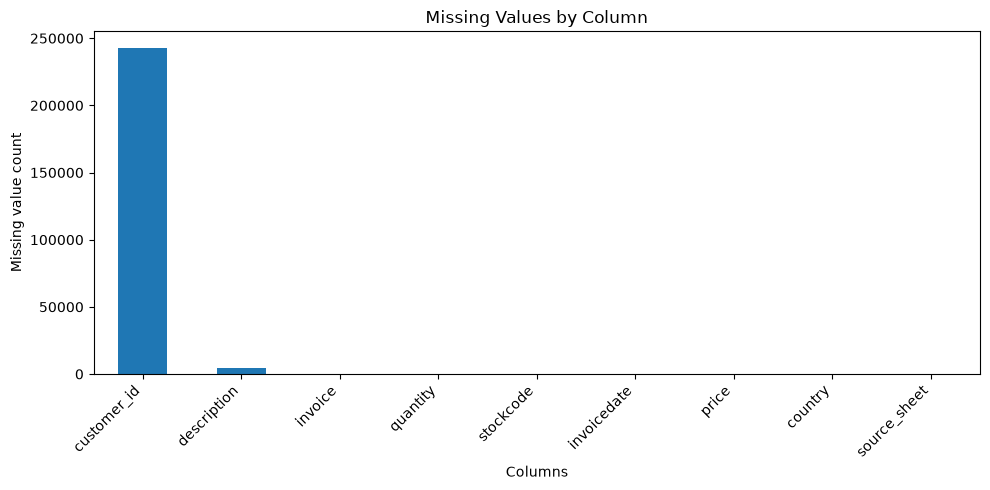

In [18]:
missing_report["missing_count"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Missing Values by Column"
)

plt.xlabel("Columns")
plt.ylabel("Missing value count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [19]:
duplicate_count = df_clean_names.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

duplicate_rows = df_clean_names[
    df_clean_names.duplicated(keep=False)
]

display(duplicate_rows.head(10))

Exact duplicate rows: 12133


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom,Year 2009-2010
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom,Year 2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom,Year 2009-2010
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,"16,329.00",United Kingdom,Year 2009-2010
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,"16,329.00",United Kingdom,Year 2009-2010
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom,Year 2009-2010
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,"16,329.00",United Kingdom,Year 2009-2010
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,"16,329.00",United Kingdom,Year 2009-2010
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,"16,329.00",United Kingdom,Year 2009-2010
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom,Year 2009-2010


In [ ]:
# Quantity aur Price ke data types verify karna
analysis_df = df_clean_names.copy()

analysis_df["quantity"] = pd.to_numeric(
    analysis_df["quantity"],
    errors="coerce"
)

analysis_df["price"] = pd.to_numeric(
    analysis_df["price"],
    errors="coerce"
)

print(analysis_df[["quantity", "price"]].dtypes)

quantity      int64
price       float64
dtype: object


In [21]:
quantity_summary = pd.Series({
    "negative_quantity_rows": (analysis_df["quantity"] < 0).sum(),
    "zero_quantity_rows": (analysis_df["quantity"] == 0).sum(),
    "positive_quantity_rows": (analysis_df["quantity"] > 0).sum(),
    "missing_quantity_rows": analysis_df["quantity"].isna().sum()
})

display(quantity_summary.to_frame("row_count"))

,row_count
negative_quantity_rows,22950
zero_quantity_rows,0
positive_quantity_rows,1044421
missing_quantity_rows,0


In [22]:
price_summary = pd.Series({
    "negative_price_rows": (analysis_df["price"] < 0).sum(),
    "zero_price_rows": (analysis_df["price"] == 0).sum(),
    "positive_price_rows": (analysis_df["price"] > 0).sum(),
    "missing_price_rows": analysis_df["price"].isna().sum()
})

display(price_summary.to_frame("row_count"))

,row_count
negative_price_rows,5
zero_price_rows,6202
positive_price_rows,1061164
missing_price_rows,0


In [23]:
analysis_df["invoice"] = analysis_df["invoice"].astype("string").str.strip()

cancellation_mask = analysis_df["invoice"].str.startswith(
    "C",
    na=False
)

print("Cancellation invoice rows:", cancellation_mask.sum())
display(analysis_df.loc[cancellation_mask].head(10))

Cancellation invoice rows: 19494


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,"16,321.00",Australia,Year 2009-2010
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,"16,321.00",Australia,Year 2009-2010
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,"16,321.00",Australia,Year 2009-2010
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia,Year 2009-2010
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia,Year 2009-2010
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,"16,321.00",Australia,Year 2009-2010
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,"17,592.00",United Kingdom,Year 2009-2010


In [24]:
# Invoice date ko datetime mein convert karna
analysis_df["invoicedate"] = pd.to_datetime(
    analysis_df["invoicedate"],
    errors="coerce"
)

print("Date data type:", analysis_df["invoicedate"].dtype)
print("Invalid/missing dates:", analysis_df["invoicedate"].isna().sum())
print("Earliest date:", analysis_df["invoicedate"].min())
print("Latest date:", analysis_df["invoicedate"].max())

Date data type: datetime64[us]
Invalid/missing dates: 0
Earliest date: 2009-12-01 07:45:00
Latest date: 2011-12-09 12:50:00


,unique_invoice_count
invoicedate,
2009-12-01,2330
2010-01-01,1633
2010-02-01,1969
2010-03-01,2367
2010-04-01,1892
2010-05-01,2418
2010-06-01,2216
2010-07-01,2017
2010-08-01,1877


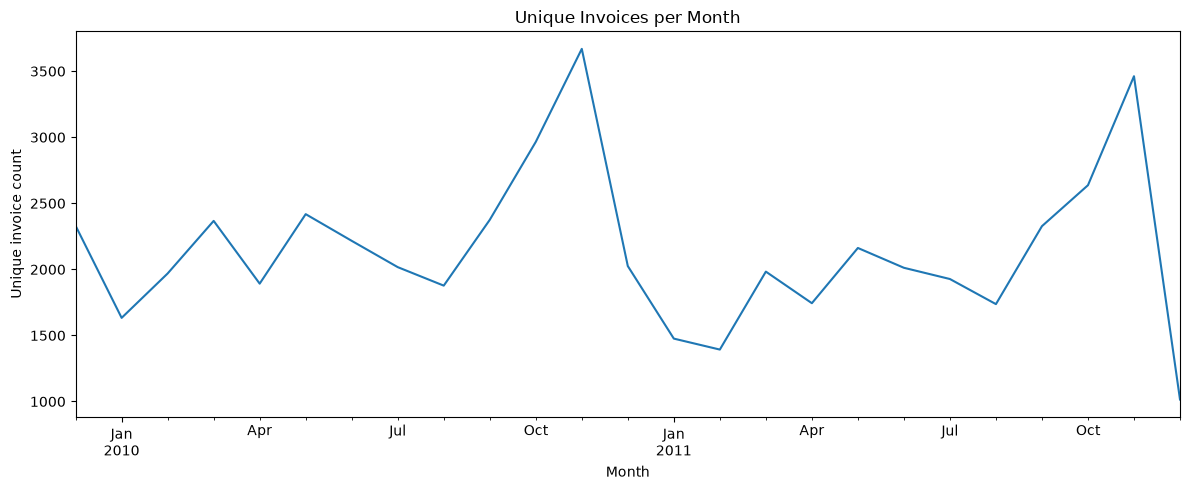

In [25]:
# Monthly invoice trend dekhna
monthly_invoices = (
    analysis_df.dropna(subset=["invoicedate"])
    .set_index("invoicedate")
    .resample("MS")["invoice"]
    .nunique()
)

display(monthly_invoices.to_frame("unique_invoice_count"))

monthly_invoices.plot(
    figsize=(12, 5),
    title="Unique Invoices per Month"
)

plt.xlabel("Month")
plt.ylabel("Unique invoice count")
plt.tight_layout()
plt.show()

In [26]:
# Customer, product aur country counts
print("Unique customers:", analysis_df["customer_id"].nunique())
print("Unique stock codes:", analysis_df["stockcode"].nunique())
print("Unique countries:", analysis_df["country"].nunique())

print("Top 10 countries by row count:")
display(analysis_df["country"].value_counts().head(10).to_frame("row_count"))

print("Top 10 stock codes by row count:")
display(analysis_df["stockcode"].value_counts().head(10).to_frame("row_count"))

Unique customers: 5942
Unique stock codes: 5305
Unique countries: 43
Top 10 countries by row count:


,row_count
country,
United Kingdom,981330
EIRE,17866
Germany,17624
France,14330
Netherlands,5140
Spain,3811
Switzerland,3189
Belgium,3123
Portugal,2620


Top 10 stock codes by row count:


,row_count
stockcode,
85123A,5829
22423,4424
85099B,4216
21212,3318
20725,3259
84879,2960
47566,2768
21232,2747
22197,2549


In [ ]:
# Initial data-quality report banana
quality_report = pd.DataFrame([
    ["Total rows", len(analysis_df)],
    ["Total columns", len(analysis_df.columns)],
    ["Exact duplicate rows", analysis_df.duplicated().sum()],
    ["Missing customer IDs", analysis_df["customer_id"].isna().sum()],
    ["Missing descriptions", analysis_df["description"].isna().sum()],
    ["Negative quantities", (analysis_df["quantity"] < 0).sum()],
    ["Zero quantities", (analysis_df["quantity"] == 0).sum()],
    ["Zero prices", (analysis_df["price"] == 0).sum()],
    ["Negative prices", (analysis_df["price"] < 0).sum()],
    ["Cancellation invoice rows", cancellation_mask.sum()],
    ["Invalid/missing invoice dates", analysis_df["invoicedate"].isna().sum()]
], columns=["check", "value"])

display(quality_report)

,check,value
0,Total rows,1067371
1,Total columns,9
2,Exact duplicate rows,12133
3,Missing customer IDs,243007
4,Missing descriptions,4382
5,Negative quantities,22950
6,Zero quantities,0
7,Zero prices,6202
8,Negative prices,5
9,Cancellation invoice rows,19494


In [28]:
OUTPUT_DIR = Path("../data/interim")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

quality_report.to_csv(
    OUTPUT_DIR / "initial_data_quality_report.csv",
    index=False
)

missing_report.to_csv(
    OUTPUT_DIR / "missing_values_report.csv"
)

print("Reports saved in:", OUTPUT_DIR.resolve())

Reports saved in: D:\loyality_reward_optimization\data\interim


In [29]:
print("DATASET UNDERSTANDING SUMMARY")
print("-" * 40)
print("Total rows:", analysis_df.shape[0])
print("Total columns:", analysis_df.shape[1])
print("Unique customers:", analysis_df["customer_id"].nunique())
print("Unique products:", analysis_df["stockcode"].nunique())
print("Missing customer IDs:", analysis_df["customer_id"].isna().sum())
print("Duplicate rows:", analysis_df.duplicated().sum())
print("Negative quantity rows:", (analysis_df["quantity"] < 0).sum())
print("Cancellation invoice rows:", cancellation_mask.sum())
print("Date range:", analysis_df["invoicedate"].min(), "to", analysis_df["invoicedate"].max())

DATASET UNDERSTANDING SUMMARY
----------------------------------------
Total rows: 1067371
Total columns: 9
Unique customers: 5942
Unique products: 5305
Missing customer IDs: 243007
Duplicate rows: 12133
Negative quantity rows: 22950
Cancellation invoice rows: 19494
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [30]:
# Cancellation aur normal invoices ka comparison
analysis_df["invoice"] = analysis_df["invoice"].astype(str)

analysis_df["is_cancelled"] = (
    analysis_df["invoice"].str.startswith("C")
)

display(
    analysis_df["is_cancelled"].value_counts()
)

is_cancelled
False    1047877
True       19494
Name: count, dtype: int64

In [31]:
# Returns inspect karna
returns_df = analysis_df[
    analysis_df["quantity"] < 0
]

display(returns_df.head(10))

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet,is_cancelled
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010,True
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,"16,321.00",Australia,Year 2009-2010,True
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,"16,321.00",Australia,Year 2009-2010,True
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,"16,321.00",Australia,Year 2009-2010,True
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010,True
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia,Year 2009-2010,True
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia,Year 2009-2010,True
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,"16,321.00",Australia,Year 2009-2010,True
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia,Year 2009-2010,True
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,"17,592.00",United Kingdom,Year 2009-2010,True


In [32]:
# Missing Customer IDs inspect karna
missing_customers = analysis_df[
    analysis_df["customer_id"].isna()
]

display(missing_customers.head(10))

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet,is_cancelled
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom,Year 2009-2010,False
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom,Year 2009-2010,False
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom,Year 2009-2010,False
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom,Year 2009-2010,False
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom,Year 2009-2010,False
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom,Year 2009-2010,False
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom,Year 2009-2010,False
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom,Year 2009-2010,False
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom,Year 2009-2010,False
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom,Year 2009-2010,False


In [33]:
# Zero aur negative prices inspect karna
invalid_price_df = analysis_df[
    analysis_df["price"] <= 0
]

display(invalid_price_df.head(20))

,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet,is_cancelled
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom,Year 2009-2010,False
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom,Year 2009-2010,False
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom,Year 2009-2010,False
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom,Year 2009-2010,False
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom,Year 2009-2010,False
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.00,NaN,United Kingdom,Year 2009-2010,False
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.00,NaN,United Kingdom,Year 2009-2010,False
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.00,NaN,United Kingdom,Year 2009-2010,False
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.00,NaN,United Kingdom,Year 2009-2010,False
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.00,NaN,United Kingdom,Year 2009-2010,False
